In [ ]:
!gdown 1ZRbI4ZixHQzyglhDOSIuGjq3aXLDAAa0
!unzip -q 44dataset.zip

Downloading...
From (original): https://drive.google.com/uc?id=1ZRbI4ZixHQzyglhDOSIuGjq3aXLDAAa0
From (redirected): https://drive.google.com/uc?id=1ZRbI4ZixHQzyglhDOSIuGjq3aXLDAAa0&confirm=t&uuid=cf091022-8589-4fde-ad93-17f06a7b03e9
To: /content/44dataset.zip
100% 197M/197M [00:15<00:00, 12.9MB/s]


In [ ]:
import torch
from torch.utils.data import DataLoader, random_split
from torchvision.datasets import ImageFolder
from torchvision.transforms import v2
from tqdm.notebook import tqdm

def get_transform(path):
    dataset = ImageFolder(path, transform=v2.Compose([
        v2.Resize(size=(224, 224)),
        v2.PILToTensor(),
        v2.ToDtype(torch.float32, scale=True)
    ]))

    mean = torch.zeros(3)
    for image, _ in tqdm(dataset, "Computing mean"):
        mean += image.mean(dim=(1, 2))
    mean /= len(dataset)

    mean_img = mean.view(3, 1, 1).expand(-1, 224, 224)

    std = torch.zeros(3)
    for image, _ in tqdm(dataset, "Computing std"):
        d = image - mean_img
        std += (d * d).mean(dim=(1, 2))
    std = torch.sqrt((std / len(dataset)))

    print(mean, std)

    transform_augment = v2.Compose([
        v2.Resize(size=(224, 224)),
        # v2.RandomRotation(degrees=7.2),
        v2.RandomHorizontalFlip(),
        # v2.RandomVerticalFlip(),

        v2.PILToTensor(),
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize(mean, std)
    ])

    transform = v2.Compose([
        v2.Resize(size=(224, 224)),
        v2.PILToTensor(),
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize(mean, std)
    ])

    return transform_augment, transform

transform_augment, transform = get_transform("44_classes/Training")

rng = torch.Generator().manual_seed(42)
dataset = ImageFolder("44_classes/Training", transform=transform_augment)

Computing mean:   0%|          | 0/3117 [00:00<?, ?it/s]

Computing std:   0%|          | 0/3117 [00:00<?, ?it/s]

tensor([0.1848, 0.1848, 0.1848]) tensor([0.2034, 0.2034, 0.2034])


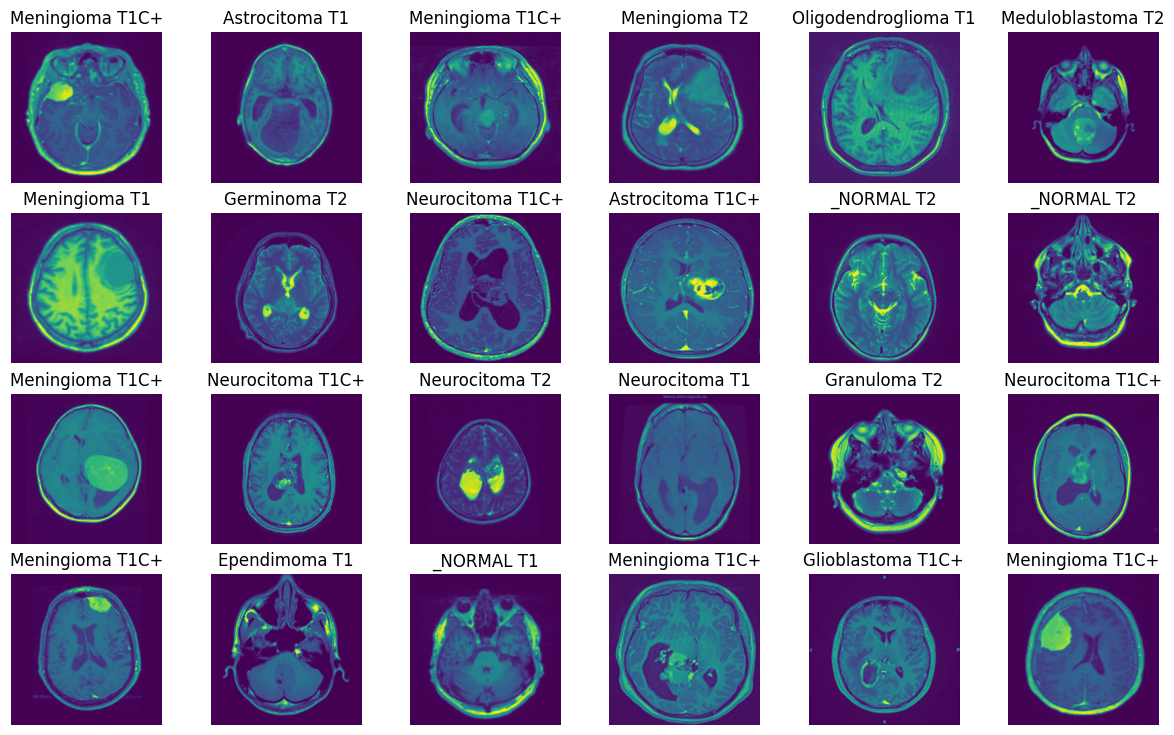

In [ ]:
import matplotlib.pyplot as plt

def visualize(dataset):
    n_rows = 4
    n_cols = 6
    rng = torch.Generator().manual_seed(42)
    loader = DataLoader(dataset, n_rows * n_cols, True, generator=rng)

    imgs, labels = next(iter(loader))

    imgs = imgs.view([n_rows, n_cols] + list(imgs.shape[1:]))
    labels = labels.view([n_rows, n_cols] + list(labels.shape[1:]))

    fig, ax = plt.subplots(n_rows, n_cols, figsize=(15, 9))
    for i in range(n_rows):
        for j in range(n_cols):
            ax[i][j].imshow(imgs[i][j].mean(dim=0))
            ax[i][j].set_title(dataset.classes[labels[i][j].item()])
            ax[i][j].axis("off")

    return fig

visualize(dataset).show()

In [ ]:
def evaluate(name, model, loader, loss_fn, metric_fn, device):
    model.eval()
    with torch.no_grad():
        valid_loss = 0
        valid_metric = 0
        pbar = tqdm(loader)
        for i, (images, labels) in enumerate(pbar):
            images = images.to(device)
            labels = labels.to(device)

            preds = model(images)
            loss = loss_fn(preds, labels)
            metric = metric_fn(preds, labels)

            valid_loss = valid_loss + loss.item()
            valid_metric = valid_metric + metric.item()
            pbar.set_description(f"[{name}] Loss: {valid_loss / (i + 1):.4f} - Metric: {valid_metric / (i + 1):.4f}")

        return valid_loss / (i + 1), valid_metric / (i + 1)


class TrainResult:
    def __init__(self):
        self.train_loss = []
        self.train_metric = []
        self.valid_loss = []
        self.valid_metric = []
        self.best_metric = 0.0


def train(model, train_loader, valid_loader, optimizer, scheduler, loss_fn, metric_fn, epochs, device):
    hist = TrainResult()

    for epoch in range(epochs):
        print(f"Epoch {epoch + 1}/{epochs}:")
        model.train()
        train_loss = 0
        train_metric = 0
        pbar = tqdm(train_loader)
        for i, (images, labels) in enumerate(pbar):
            images = images.to(device)
            labels = labels.to(device)

            preds = model(images)
            loss = loss_fn(preds, labels)
            metric = metric_fn(preds, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            train_loss = (train_loss + loss.item())
            train_metric = (train_metric + metric.item())
            pbar.set_description(f"[Training] Loss: {train_loss / (i + 1):.4f} - Metric: {train_metric / (i + 1):.4f}")
        if scheduler:
            scheduler.step()

        hist.train_loss.append(train_loss / (i + 1))
        hist.train_metric.append(train_metric / (i + 1))

        valid_loss, valid_metric = evaluate("Validation", model, valid_loader, loss_fn, metric_fn, device)
        hist.valid_loss.append(valid_loss)
        hist.valid_metric.append(valid_metric)
        if valid_metric > hist.best_metric:
            hist.best_metric = valid_metric
            hist.best_model = model.state_dict()

    hist.last_model = model.state_dict()
    return hist

In [ ]:
from torchvision.models import efficientnet_b3, EfficientNet_B3_Weights
from torch import nn

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

def get_weights(dataset):
    weights = torch.zeros(len(dataset.classes))
    for _, label in tqdm(dataset, "Computing cross entropy weights"):
        weights[label] += 1

    return len(dataset) / (len(dataset.classes) * weights)

def create_model_resnet(d_output):
    model = efficientnet_b3(weights=EfficientNet_B3_Weights.DEFAULT)
    in_features = model.classifier[1].in_features
    model.classifier = nn.Sequential(
        nn.BatchNorm1d(in_features),
        nn.Linear(in_features, 256, bias=False),
        nn.BatchNorm1d(256),
        nn.ReLU(),
        nn.Linear(256, d_output),
    )
    return model

def accuracy(preds, labels):
    return (preds.argmax(dim=1) == labels).float().mean()

torch.manual_seed(42)

model = create_model_resnet(len(dataset.classes)).to(device)

rng = torch.Generator().manual_seed(42)
train_dataset, valid_dataset = random_split(dataset, [0.8, 0.2], generator=rng)
train_loader = DataLoader(train_dataset, 64, True, generator=rng)
valid_loader = DataLoader(valid_dataset, 64, True, generator=rng)

adam = torch.optim.Adam(model.parameters(), lr=3e-4)
criterion = nn.CrossEntropyLoss(get_weights(dataset).to(device))

hist = train(model, train_loader, valid_loader, adam, None, criterion, accuracy, 20, device)

In [ ]:
def visualize_learning(hist):
    fig, ax = plt.subplots(1, 2, figsize=(15, 7))
    ax[0].plot(range(len(hist.train_loss)), hist.train_loss, label="training")
    ax[0].plot(range(len(hist.valid_loss)), hist.valid_loss, label="validation")
    ax[0].set_title("Loss")
    ax[0].legend()

    ax[1].plot(range(len(hist.train_metric)), hist.train_metric, label="training")
    ax[1].plot(range(len(hist.valid_metric)), hist.valid_metric, label="validation")
    ax[1].set_title("Accuracy")
    ax[1].legend()

    return fig

visualize_learning(hist).show()

In [ ]:
import seaborn as sn
import pandas as pd

def visualize_test(test_dataset, dataset):
    confusion_matrix = torch.zeros((len(dataset.classes), len(dataset.classes)))
    correct = 0
    pbar = tqdm(test_dataset)

    for i, (image, label) in enumerate(pbar):
        model.load_state_dict(hist.best_model)
        model.eval()
        pred = model(image.unsqueeze(0).to(device)).argmax(1).item()
        label = dataset.class_to_idx[test_dataset.classes[label]]
        confusion_matrix[label][pred] += 1
        if pred == label:
            correct += 1
        pbar.set_description(f"Accuracy: {correct * 100 / (i + 1):.4f}%")

    fig, ax = plt.subplots(figsize=(12, 12))
    df = pd.DataFrame(confusion_matrix, index=dataset.classes, columns=dataset.classes)
    sn.heatmap(df, square=True)
    print(correct / len(test_dataset))

test_dataset = ImageFolder("44_classes/Testing", transform=transform)
visualize_test(test_dataset, dataset)